# Deliverable 2

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Import the dataset
data = pd.read_csv('StudentPerformanceFactors.csv')

# Correct invalid Exam_Score values above 100
data.loc[data['Exam_Score'] > 100, 'Exam_Score'] = 100

# Create a random sample of 4000 students
d2_sample = data.sample(n=4000, replace=False, random_state=42)

# Select the relevant columns
selected_data = d2_sample[
    ['Hours_Studied',
     'Attendance',
     'Previous_Scores',
     'Tutoring_Sessions',
     'Sleep_Hours',
     'Exam_Score']
]

# Separate independent and dependent variables
X = selected_data.iloc[:, :-1].values
y = selected_data.iloc[:, -1].values

print(X)
print(y)

[[20 71 87  1  7]
 [22 71 98  2  7]
 [21 91 53  1  6]
 ...
 [20 95 99  1  8]
 [25 77 71  0  7]
 [19 87 74  1  4]]
[65 65 71 ... 70 66 69]


In [2]:
# Check for missing values
selected_data.isnull().sum()

Hours_Studied        0
Attendance           0
Previous_Scores      0
Tutoring_Sessions    0
Sleep_Hours          0
Exam_Score           0
dtype: int64

In [3]:
# Check the data types of the selected variables
print(selected_data.dtypes)

Hours_Studied        int64
Attendance           int64
Previous_Scores      int64
Tutoring_Sessions    int64
Sleep_Hours          int64
Exam_Score           int64
dtype: object


In [4]:
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 3200
Testing records: 800


In [5]:
from sklearn.preprocessing import StandardScaler

# Apply feature scaling
sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

print(X_train_scaled)
print(X_test_scaled)

[[ 0.83879148  1.21846179  0.75813678  0.4238641  -0.00528342]
 [-1.85358666  0.87049296 -0.71197696  1.2404596   1.34727213]
 [ 2.01670691  0.69650855 -1.20201487  1.2404596   0.67099435]
 ...
 [-1.34876576  1.65342283  1.31818011  0.4238641  -0.68156119]
 [ 0.67051784  1.305454   -0.64197154  0.4238641  -0.00528342]
 [-0.67567122 -1.65228106 -1.48203653 -0.3927314  -2.03411674]]
[[-0.84394486 -0.17341353 -0.85198779  0.4238641   1.34727213]
 [ 0.33397058 -0.17341353  1.17816927 -0.3927314  -0.68156119]
 [-0.33912396  0.08756309 -0.71197696  0.4238641   0.67099435]
 ...
 [-0.17085032 -0.43439015 -0.78198237  0.4238641  -0.68156119]
 [ 0.83879148 -1.56528885  0.12808803 -1.2093269   0.67099435]
 [-0.33912396  1.305454    1.31818011  3.69024609 -0.68156119]]


# regression model

In [6]:
import pandas as pd

# Load the dataset
data = pd.read_csv('StudentPerformanceFactors.csv')

# Correct invalid Exam_Score
data.loc[data['Exam_Score'] > 100, 'Exam_Score'] = 100

# Create a random sample of 4000 students
regression_data = data.sample(n=4000, replace=False, random_state=42)

# Select relevant columns
regression_data = regression_data[
    ['Hours_Studied',
     'Attendance',
     'Previous_Scores',
     'Tutoring_Sessions',
     'Sleep_Hours',
     'Exam_Score']
]



# Display the first few rows
print(regression_data.head())

      Hours_Studied  Attendance  Previous_Scores  Tutoring_Sessions  \
743              20          71               87                  1   
5551             22          71               98                  2   
3442             21          91               53                  1   
6571             12          91               81                  0   
4204             21          63               95                  2   

      Sleep_Hours  Exam_Score  
743             7          65  
5551            7          65  
3442            6          71  
6571            8          64  
4204            8          66  


In [7]:
# Check for missing values
print(regression_data.isnull().sum())


Hours_Studied        0
Attendance           0
Previous_Scores      0
Tutoring_Sessions    0
Sleep_Hours          0
Exam_Score           0
dtype: int64


In [8]:
# Detect outliers using the IQR method

def detect_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    return data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]


# Detect outliers in all independent variables
outliers_list = []

for col in ['Hours_Studied',
            'Attendance',
            'Previous_Scores',
            'Tutoring_Sessions',
            'Sleep_Hours']:

    outliers_list.append(
        detect_outliers(regression_data, col)
    )


# Combine the outliers and remove duplicates
outliers = pd.concat(outliers_list).drop_duplicates()

print("Number of outlier records:", len(outliers))

# Remove the outlier records
regression_data_no_outliers = regression_data[
    ~regression_data.index.isin(outliers.index)
]

print("Records before removing outliers:", len(regression_data))
print("Records after removing outliers:", len(regression_data_no_outliers))

Number of outlier records: 285
Records before removing outliers: 4000
Records after removing outliers: 3715


In [9]:
from sklearn.model_selection import train_test_split

# Define independent variables
X = regression_data_no_outliers[
    ['Hours_Studied',
     'Attendance',
     'Previous_Scores',
     'Tutoring_Sessions',
     'Sleep_Hours']
]

# Define dependent variable
y = regression_data_no_outliers['Exam_Score']

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 2972
Testing records: 743


## 1.	Multiple Linear Regression:

In [10]:
from sklearn.linear_model import LinearRegression

# Multiple Linear Regression
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

print(y_pred_linear)

[71.50114135 67.77502971 66.73588519 63.17580857 65.79045916 66.99424351
 65.82676498 68.20579348 67.37859908 66.67223695 68.82702647 66.18260223
 66.79590756 68.18011596 64.4971548  64.22690972 71.25039581 65.75877935
 74.1819413  67.82438015 73.29727879 66.58969555 66.09956125 70.4549409
 61.67844804 71.14440913 69.44635198 66.76764235 64.06026625 63.56400405
 69.50123018 71.23832964 65.50189137 67.47266991 72.5330437  69.25550133
 66.01810253 64.8239399  72.05693372 64.28561303 64.5441251  62.19136992
 66.20794317 67.08575978 64.33717837 66.36283295 65.92600907 66.24561727
 70.9495926  69.67741181 63.97737343 64.6580382  68.58767605 64.91352363
 64.44895392 66.27949932 62.6406875  64.2300054  67.88358396 66.20232977
 64.93974245 70.15524241 63.0403035  65.28937266 66.68919053 63.17893143
 68.21479553 66.97628552 69.77027094 67.68795944 64.34747105 63.6330266
 67.71874459 63.41365056 68.58912073 62.17201768 62.67082056 71.43820186
 60.04617087 69.13360856 67.72656864 71.42071216 68.6

## 2.	Polynomial Regression (Degree 2):

In [11]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Polynomial Regression
poly_features = PolynomialFeatures(degree=2)

X_poly_train = poly_features.fit_transform(X_train)
X_poly_test = poly_features.transform(X_test)

polynomial_model = LinearRegression()

polynomial_model.fit(X_poly_train, y_train)

y_pred_polynomial = polynomial_model.predict(X_poly_test)

print(y_pred_polynomial)

[71.55329557 67.75971356 66.6858621  63.25805051 65.6752284  66.77702809
 65.79371973 68.07858138 67.34078978 66.55502305 68.64214804 66.09601008
 66.78581065 67.94684422 64.54691442 64.12074083 71.30342946 65.63587095
 74.30590064 68.11230689 73.89859943 66.43443198 65.92253798 70.54029596
 61.61416785 71.28961547 69.67782334 66.62907417 63.83467848 63.73245564
 69.51915736 71.58971364 65.35071028 67.38138889 72.62477336 69.14893445
 66.19779885 64.80321146 72.17315275 64.54813804 64.65564395 62.19369936
 66.1808246  67.17414846 64.30077638 66.34123461 65.87352772 66.17250315
 71.07673662 69.70113269 63.88302284 64.36428777 68.75655545 64.82261523
 64.38481084 66.45933024 62.64670928 64.16959926 67.82595458 65.62463873
 64.74403329 70.12623355 62.9559355  65.14907772 66.6130269  63.33865426
 68.15632653 67.0193303  69.88817533 67.62425716 64.26084503 63.41836416
 67.63266681 63.45382847 68.57577804 62.63338754 62.92072311 71.22804182
 60.60991172 69.15030351 67.63336863 71.71393334 68

## 3.	Ridge Regression:

In [12]:
from sklearn.linear_model import Ridge

# Ridge Regression
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)

print(y_pred_ridge)

[71.50116382 67.7752413  66.73608238 63.1758775  65.79050517 66.99427364
 65.82664787 68.20582479 67.37862184 66.6722821  68.82675194 66.18281618
 66.79562863 68.17985143 64.49689525 64.22711909 71.25025837 65.7588423
 74.18179054 67.82442429 73.29744118 66.58991326 66.09960829 70.45464476
 61.67868219 71.14426933 69.4465541  66.76768329 64.06048194 63.56405981
 69.50110554 71.23850188 65.50209546 67.47255628 72.5328936  69.25538801
 66.01830801 64.8236915  72.05679959 64.28565894 64.54401143 62.19143287
 66.20799738 67.08563625 64.33740602 66.36286707 65.92604681 66.24535096
 70.94947059 69.67745369 63.97742472 64.65822832 68.58770778 64.91341113
 64.44899686 66.27923293 62.64074919 64.23005602 67.88346754 66.20252009
 64.93996646 70.15511132 63.04036613 65.28958369 66.68892376 63.17883314
 68.21483726 66.97616583 69.77045384 67.68784295 64.34751933 63.63323931
 67.71895163 63.4135589  68.58914185 62.17193183 62.67074445 71.43807122
 60.04609409 69.13380837 67.72677393 71.42073104 68.

## 4.	Lasso Regression:

In [13]:
from sklearn.linear_model import Lasso

# Lasso Regression
lasso_model = Lasso(alpha=0.1)

lasso_model.fit(X_train, y_train)

y_pred_lasso = lasso_model.predict(X_test)

print(y_pred_lasso)

[71.50484134 67.93477183 66.86077486 63.26335947 65.81081067 66.97257121
 65.73503647 68.23641164 67.39632111 66.69011304 68.65521012 66.33119571
 66.59322923 67.99819023 64.31820282 64.35355786 71.1820032  65.80579957
 74.08577929 67.85569119 73.36736521 66.77027308 66.1567051  70.2467652
 61.87672401 71.02475873 69.580298   66.80820271 64.23221881 63.61643499
 69.39512825 71.35610603 65.65604191 67.39989004 72.38896318 69.18277624
 66.13421703 64.70878551 71.93762539 64.31814313 64.44424461 62.24612886
 66.23997993 66.99779749 64.49086084 66.35361554 65.95705645 66.09561261
 70.84038051 69.69540079 64.03402615 64.76351382 68.57621556 64.85852935
 64.50074846 66.09943021 62.69461434 64.28668059 67.77611056 66.36327233
 65.08445566 70.0576816  63.06803961 65.43479296 66.51816901 63.10483279
 68.25014853 66.89076355 69.87552776 67.607288   64.36937602 63.79091441
 67.85258758 63.35081733 68.57951081 62.14995903 62.66569838 71.38165185
 60.02061018 69.27030899 67.85976866 71.38839929 68.

## 5.	Elastic Net Regression:

In [14]:
from sklearn.linear_model import ElasticNet

# Elastic Net Regression
elastic_model = ElasticNet(
    alpha=0.1,
    l1_ratio=0.5
)

elastic_model.fit(X_train, y_train)

y_pred_elastic = elastic_model.predict(X_test)

print(y_pred_elastic)

[71.50546537 67.89478997 66.8230801  63.24258091 65.79986266 66.96688477
 65.75970199 68.23202805 67.39087031 66.68014875 68.71355722 66.28388818
 66.64649873 68.0492786  64.36876742 64.30991876 71.21271978 65.79028041
 74.12803705 67.8521481  73.34512784 66.72765368 66.14795852 70.30716026
 61.82132628 71.05345231 69.5449343  66.80015885 64.18729844 63.5980062
 69.42545495 71.33200041 65.61182338 67.42223752 72.42159465 69.20491217
 66.09497526 64.75622001 71.97302543 64.30164154 64.46023409 62.22739748
 66.2242056  67.01998222 64.44257811 66.3489794  65.94682346 66.15121369
 70.87222622 69.69122018 64.01965438 64.72161247 68.56567861 64.87940107
 64.48787454 66.15619093 62.67611056 64.27220964 67.79503125 66.32753701
 65.03351795 70.08983293 63.04891912 65.38882905 66.57059422 63.11669026
 68.24444891 66.91214977 69.83897009 67.63306903 64.35806863 63.74591479
 67.81142701 63.36441212 68.58013874 62.15800363 62.67305379 71.41385485
 60.0248661  69.23348558 67.81875644 71.39268534 68.

## Evaluating models

## 1.	Multiple Linear Regression:

In [15]:
from sklearn.metrics import mean_squared_error, r2_score

mse_linear = mean_squared_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print("Multiple Linear Regression")
print("MSE:", mse_linear)
print("R-squared:", r2_linear)

Multiple Linear Regression
MSE: 3.1530067620795124
R-squared: 0.7081625574584038


## 2.	Polynomial Regression (Degree 2):

In [16]:
mse_polynomial = mean_squared_error(y_test, y_pred_polynomial)
r2_polynomial = r2_score(y_test, y_pred_polynomial)

print("Polynomial Regression")
print("MSE:", mse_polynomial)
print("R-squared:", r2_polynomial)

Polynomial Regression
MSE: 3.204374626804376
R-squared: 0.703408027131853


## 3.	Ridge Regression:

In [17]:
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression")
print("MSE:", mse_ridge)
print("R-squared:", r2_ridge)

Ridge Regression
MSE: 3.1530108571341855
R-squared: 0.7081621784264598


## 4.	Lasso Regression:

In [18]:
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression")
print("MSE:", mse_lasso)
print("R-squared:", r2_lasso)

Lasso Regression
MSE: 3.1625622075285893
R-squared: 0.7072781201664378


## 5.	Elastic Net Regression:

In [19]:
mse_elastic = mean_squared_error(y_test, y_pred_elastic)
r2_elastic = r2_score(y_test, y_pred_elastic)

print("Elastic Net Regression")
print("MSE:", mse_elastic)
print("R-squared:", r2_elastic)

Elastic Net Regression
MSE: 3.156775981839409
R-squared: 0.7078136842912623


## Comparison Table

In [20]:
results = {
    "Model": [
        "Multiple Linear Regression",
        "Polynomial Regression",
        "Ridge Regression",
        "Lasso Regression",
        "Elastic Net Regression"
    ],

    "MSE": [
        mse_linear,
        mse_polynomial,
        mse_ridge,
        mse_lasso,
        mse_elastic
    ],

    "R-squared": [
        r2_linear,
        r2_polynomial,
        r2_ridge,
        r2_lasso,
        r2_elastic
    ]
}

comparison_results = pd.DataFrame(results)

print(comparison_results)

                        Model       MSE  R-squared
0  Multiple Linear Regression  3.153007   0.708163
1       Polynomial Regression  3.204375   0.703408
2            Ridge Regression  3.153011   0.708162
3            Lasso Regression  3.162562   0.707278
4      Elastic Net Regression  3.156776   0.707814


## Best Fit Model

In [21]:
best_model = comparison_results.loc[
    comparison_results['R-squared'].idxmax()
]

print("Best-Fit Model:")
print(best_model)

Best-Fit Model:
Model        Multiple Linear Regression
MSE                            3.153007
R-squared                      0.708163
Name: 0, dtype: object


In [22]:
# Print the intercept and coefficients of the best-fit model

print("Intercept:", linear_model.intercept_)

print("Hours_Studied coefficient:", linear_model.coef_[0])
print("Attendance coefficient:", linear_model.coef_[1])
print("Previous_Scores coefficient:", linear_model.coef_[2])
print("Tutoring_Sessions coefficient:", linear_model.coef_[3])
print("Sleep_Hours coefficient:", linear_model.coef_[4])

Intercept: 41.19294988480097
Hours_Studied coefficient: 0.2983358044785855
Attendance coefficient: 0.19668559909889435
Previous_Scores coefficient: 0.04691307512274205
Tutoring_Sessions coefficient: 0.45137134688834696
Sleep_Hours coefficient: 0.014253865923230226


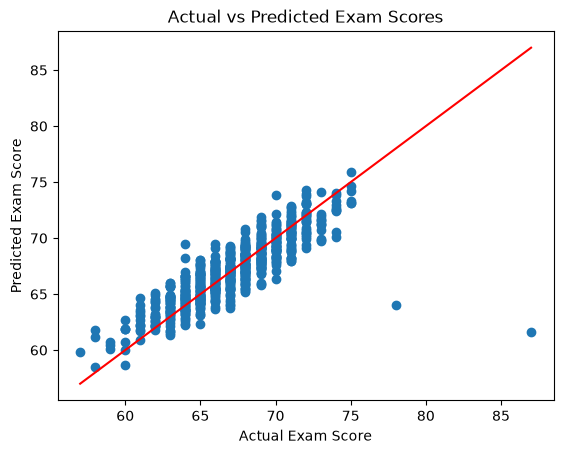

In [23]:
import matplotlib.pyplot as plt

# Plot actual vs predicted Exam_Score
plt.scatter(y_test, y_pred_linear)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel('Actual Exam Score')
plt.ylabel('Predicted Exam Score')
plt.title('Actual vs Predicted Exam Scores')

plt.show()

# Classification Model 

#### Classifying the dataset based on the target variable 

In [24]:
import numpy as np

# Create classification dataset from the 4000-student sample
classification_data = d2_sample.copy()

# Find the median Exam_Score
threshold = classification_data['Exam_Score'].median()

# Create categorical target variable
classification_data['Target'] = np.where(
    classification_data['Exam_Score'] >= threshold,
    1,
    0
)

print("Threshold:", threshold)
print("High Performance:", (classification_data['Target'] == 1).sum())
print("Low Performance:", (classification_data['Target'] == 0).sum())

Threshold: 67.0
High Performance: 2256
Low Performance: 1744


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Define independent variables
X = classification_data[
    ['Hours_Studied',
     'Attendance',
     'Previous_Scores',
     'Tutoring_Sessions',
     'Sleep_Hours']
]

# Define categorical target variable
y = classification_data['Target']

# Check the number of students in each category
print("Pass:", (y == 1).sum())
print("Fail:", (y == 0).sum())

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
)

# Feature Scaling
sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Pass: 2256
Fail: 1744
Training records: 3200
Testing records: 800


### 	Preparing the Classification Data

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Define independent variables
X = classification_data[
    ['Hours_Studied',
     'Attendance',
     'Previous_Scores',
     'Tutoring_Sessions',
     'Sleep_Hours']
]

# Define target variable
y = classification_data['Target']

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
)

# Feature Scaling
sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 3200
Testing records: 800


### 1.	Logistic Regression

In [27]:
from sklearn.linear_model import LogisticRegression

# Logistic Regression
logistic_model = LogisticRegression(random_state=0)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

# Predict the test set
y_pred_logistic = logistic_model.predict(X_test_scaled)

print(y_pred_logistic)

[0 1 0 0 0 1 0 1 0 1 1 1 1 1 1 1 0 1 1 1 1 1 1 0 1 0 0 1 0 0 1 1 1 1 0 0 1
 0 1 1 1 0 1 0 1 1 0 1 0 1 0 1 0 0 1 1 0 1 1 0 1 0 1 1 1 1 1 0 1 1 0 1 0 1
 1 1 1 0 1 1 0 1 1 1 1 0 1 1 0 0 0 1 0 0 1 1 0 1 1 0 0 1 0 1 0 0 1 0 1 1 0
 1 1 0 1 0 0 1 0 1 1 1 1 0 1 1 1 0 1 1 0 1 0 0 1 1 1 0 0 1 1 1 0 1 0 1 1 0
 0 1 0 1 0 1 0 1 0 1 0 1 0 1 1 1 0 0 1 0 1 1 1 1 1 0 1 0 1 1 1 0 0 1 1 0 1
 1 1 0 1 0 0 1 0 0 1 1 1 0 1 1 0 1 1 0 0 0 0 1 0 0 1 0 1 1 0 1 1 1 0 1 1 0
 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 1 0 0 1 0 1 1 0 0
 1 0 0 1 0 0 0 1 0 0 0 1 0 1 1 1 0 1 0 1 1 1 1 0 0 1 0 1 1 0 1 1 1 1 1 0 0
 1 1 0 0 0 1 0 1 0 0 1 0 1 0 1 1 0 1 1 1 0 1 1 1 1 0 1 1 1 0 1 0 0 0 0 1 1
 0 0 1 0 0 0 1 0 1 0 0 1 1 0 1 1 1 0 1 0 1 0 1 1 0 0 0 0 1 0 0 0 1 0 0 1 0
 0 0 1 0 1 1 0 0 1 0 1 1 1 0 1 0 0 0 0 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 1
 1 1 0 1 1 1 1 1 1 1 1 1 1 0 0 0 1 1 0 1 1 1 1 0 0 0 1 1 0 0 1 0 1 0 0 0 0
 0 1 1 1 0 0 0 1 1 1 1 1 1 0 1 1 0 1 1 0 1 1 1 1 1 1 0 0 1 1 0 1 0 1 0 0 1
 0 1 1 0 0 1 1 1 1 1 1 0 

### 2.	K-Nearest Neighbors (KNN)

In [28]:
from sklearn.neighbors import KNeighborsClassifier

# K-Nearest Neighbors
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='minkowski',
    p=2
)

# Train the model
knn_model.fit(X_train_scaled, y_train)

# Predict the test set
y_pred_knn = knn_model.predict(X_test_scaled)

print(y_pred_knn)

[0 1 1 0 0 1 0 1 0 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 0 0 1 0 0 1 1 1 1 0 0 1
 0 1 1 1 0 1 0 1 1 0 1 0 1 0 1 0 0 1 1 0 1 1 0 1 0 1 1 1 1 1 0 1 1 0 1 0 1
 1 1 1 0 1 1 0 1 1 1 1 0 1 1 0 0 0 1 0 0 1 1 0 1 1 0 0 1 0 1 0 0 1 0 1 1 0
 1 1 0 1 1 0 1 0 1 1 1 1 0 0 1 1 0 1 1 0 1 0 0 1 1 1 0 0 1 1 1 0 1 0 1 1 0
 0 1 0 1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 1 0 1 1 1 1 1 1 1 0 1 1 1 0 0 1 1 1 1
 1 1 1 1 0 0 1 0 0 1 1 1 1 0 1 0 1 1 0 1 0 0 1 0 0 1 0 1 0 1 1 1 1 0 1 1 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1 1 0 0 1 0 1 1 1 1 1 1 0 0 1 1 1 1 0 1
 1 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 0 1 0 1 1 1 1 1 0 1 0 1 1 0 1 1 1 1 1 0 0
 1 1 0 0 0 0 0 1 0 0 1 0 1 0 1 1 0 1 1 1 0 1 1 0 1 0 1 1 0 0 1 0 0 0 0 1 1
 0 0 1 0 0 0 1 0 1 0 0 1 1 1 1 1 1 0 1 0 1 0 1 1 0 0 1 0 1 0 0 0 1 0 0 1 0
 0 1 1 0 1 1 0 0 1 0 1 0 1 0 1 0 0 0 1 0 1 1 1 1 0 1 0 1 0 1 1 1 1 1 1 1 1
 1 1 0 1 1 1 1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 0 0 0 0 1 0 0 1 0 1 0 0 0 0
 0 0 1 1 0 0 0 1 0 1 1 1 1 0 1 0 0 1 1 0 1 1 1 1 1 1 0 0 1 1 0 1 0 1 0 0 1
 0 1 1 0 0 1 1 1 1 1 1 1 

### 3.	Support Vector Machines (SVM)

In [29]:
from sklearn.svm import SVC

# Support Vector Machine
svm_model = SVC()

# Train the model
svm_model.fit(X_train_scaled, y_train)

# Predict the test set
y_pred_svm = svm_model.predict(X_test_scaled)

print(y_pred_svm)

[0 1 1 0 0 1 0 1 0 1 1 1 1 0 1 1 0 1 1 1 1 1 1 0 1 0 0 1 0 0 1 1 1 1 0 0 1
 0 1 1 1 0 1 0 1 1 0 1 0 1 0 1 0 0 1 1 0 1 0 0 1 0 1 1 1 1 1 0 0 1 0 1 0 1
 1 1 1 0 1 1 0 1 1 1 1 0 1 1 0 0 0 1 0 0 1 1 0 1 1 0 0 1 0 1 0 0 1 0 1 1 0
 1 1 0 1 1 0 1 0 1 1 1 1 0 1 1 0 0 1 1 0 1 0 0 1 1 1 0 0 1 1 1 0 1 0 1 1 0
 0 1 0 1 0 1 0 1 1 1 0 1 0 1 1 1 0 1 1 0 1 1 1 1 1 0 1 0 1 1 1 0 0 1 1 0 1
 1 1 0 1 0 0 1 0 0 1 1 1 1 0 1 0 1 1 0 0 1 0 1 0 0 1 0 1 1 0 1 1 1 0 1 1 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1 1 0 0 1 0 1 1 1 1 1 1 0 0 1 0 1 1 0 0
 1 0 0 0 0 0 0 1 0 0 0 1 0 1 1 1 0 1 0 1 0 1 1 1 0 1 0 1 1 0 1 1 1 1 1 0 0
 1 1 0 0 0 1 0 1 0 0 1 0 1 0 1 1 0 1 1 1 0 1 1 1 1 0 1 1 1 0 1 0 0 0 0 1 1
 0 0 1 0 0 0 1 0 1 0 0 1 1 0 1 1 1 0 1 0 1 0 1 1 0 0 0 0 1 0 0 0 1 0 0 1 0
 0 0 1 0 1 1 0 0 1 0 1 1 1 0 1 0 0 1 0 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 1
 1 1 0 1 1 1 1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 0 0 0 1 1 0 0 1 0 1 0 0 0 0
 0 1 1 1 0 0 0 1 1 1 1 1 1 0 1 1 0 1 1 0 1 1 1 0 1 1 0 0 1 1 0 1 0 1 0 0 1
 0 1 1 0 0 1 1 1 1 1 1 0 

### 4.	Decision Trees

In [30]:
from sklearn.tree import DecisionTreeClassifier

# Decision Tree
decision_tree_model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=0
)

# Train the model
decision_tree_model.fit(X_train_scaled, y_train)

# Predict the test set
y_pred_tree = decision_tree_model.predict(X_test_scaled)

print(y_pred_tree)

[0 1 0 0 0 1 0 1 0 1 1 0 1 0 1 1 0 1 1 1 1 1 1 1 1 0 0 1 0 0 1 1 1 1 0 0 1
 0 1 1 0 1 0 1 1 1 1 1 0 1 0 1 0 0 1 1 0 1 0 0 1 0 1 1 1 1 0 0 1 1 0 1 0 1
 1 1 1 0 1 1 0 1 1 1 1 1 1 1 0 0 1 1 0 0 1 1 0 1 1 0 0 1 0 1 0 0 1 0 0 1 0
 1 1 0 1 0 1 1 0 1 1 1 1 1 0 0 0 1 1 1 0 1 0 0 1 1 1 0 0 1 0 1 0 1 1 1 1 0
 0 1 1 1 0 1 0 1 0 1 0 1 1 1 1 1 0 1 1 0 1 1 1 1 1 0 1 1 1 0 1 0 0 1 1 0 1
 1 1 0 1 1 1 0 1 1 1 1 1 1 0 0 0 1 1 1 0 0 0 1 0 0 1 0 1 0 1 1 1 1 0 1 1 0
 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 0 0 1 1 1 1 0 1
 1 1 0 1 0 0 0 1 0 0 0 1 1 1 0 1 0 1 0 1 1 1 1 1 0 1 0 1 1 0 1 1 1 1 1 0 0
 1 1 0 0 0 0 0 1 0 1 1 0 0 0 1 1 1 1 1 1 0 1 1 1 1 0 1 1 0 0 1 0 0 0 0 1 1
 0 0 1 0 0 0 1 0 1 0 0 1 1 0 1 1 0 0 1 0 1 0 1 1 0 0 0 1 1 0 0 0 1 0 0 1 0
 0 0 1 0 0 1 1 0 1 0 0 1 1 1 1 0 0 1 0 0 1 1 1 0 1 1 0 1 0 0 1 1 1 1 0 1 1
 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1 0 1 1 0 1 0 1 1 0 0 0 1 0 1 0 1 0 1 0 1 0 0
 0 0 1 1 0 0 0 1 1 1 1 1 1 1 0 1 0 1 1 0 1 0 1 1 1 1 0 0 0 1 0 1 0 1 0 0 1
 0 1 1 0 0 1 1 1 1 1 1 0 

### 5.	Random Forest

In [31]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest
random_forest_model = RandomForestClassifier(
    random_state=0
)

# Train the model
random_forest_model.fit(X_train_scaled, y_train)

# Predict the test set
y_pred_forest = random_forest_model.predict(X_test_scaled)

print(y_pred_forest)

[0 1 1 0 0 1 0 1 0 1 1 0 1 0 1 1 0 1 1 1 1 1 1 0 1 0 0 1 0 0 1 1 1 1 0 0 1
 0 1 1 0 1 1 0 1 1 0 1 0 1 0 1 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 0 1 1 0 1 0 1
 1 1 1 0 1 1 0 1 1 1 1 0 1 1 0 0 0 1 0 0 1 1 0 1 1 0 0 1 0 1 0 0 1 0 0 1 0
 1 1 0 1 0 0 1 0 1 1 1 1 1 1 1 0 1 1 1 0 1 0 0 1 1 1 0 0 1 1 1 0 1 0 1 1 0
 0 1 0 1 0 1 0 1 0 1 0 1 0 1 1 1 0 1 1 0 1 1 1 1 1 0 1 0 1 1 1 0 0 1 1 1 1
 1 1 0 1 0 0 1 0 0 1 1 1 1 1 0 0 1 1 1 0 0 0 1 0 0 1 0 1 1 0 1 1 1 0 1 1 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1 1 0 0 1 0 1 1 1 1 1 1 0 0 1 0 1 1 0 1
 1 0 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 1 0 1 1 1 1 1 0 1 0 1 1 0 1 1 1 1 1 0 0
 1 1 0 0 0 0 0 1 0 0 1 0 0 0 1 1 1 1 1 1 0 1 1 1 1 0 1 1 1 0 0 0 0 0 0 1 1
 0 0 1 0 0 0 1 0 1 0 0 1 1 1 1 1 1 0 1 0 1 0 1 1 0 0 0 0 1 0 0 0 1 0 0 1 0
 0 0 1 0 1 0 0 1 1 0 0 0 1 1 1 0 0 0 0 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0 1 1
 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 0 1 0 0 1 0 1 0 0 0 0
 0 0 1 1 0 0 0 1 1 1 1 1 1 1 1 1 0 1 1 0 1 1 1 0 1 1 0 0 1 1 0 1 0 1 0 0 1
 0 1 1 0 0 1 1 1 1 1 1 0 

### 6. Naïve Bayes

In [32]:
from sklearn.naive_bayes import GaussianNB

# Naive Bayes
naive_bayes_model = GaussianNB()

# Train the model
naive_bayes_model.fit(X_train_scaled, y_train)

# Predict the test set
y_pred_naive_bayes = naive_bayes_model.predict(X_test_scaled)

print(y_pred_naive_bayes)

[0 1 1 0 0 1 1 1 0 1 1 1 1 1 1 1 0 1 1 1 1 1 1 0 1 0 0 1 0 0 1 1 1 1 0 0 1
 0 1 1 1 0 1 0 1 1 0 1 0 1 0 1 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 0 1 1 0 1 0 1
 1 1 1 0 1 1 0 0 1 1 1 1 1 1 0 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1 0 0 1 0 1 1 0
 1 1 0 1 0 0 1 0 1 1 1 1 0 0 1 1 1 1 1 0 1 0 0 1 1 1 0 0 1 1 1 0 1 0 1 1 0
 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 0 1 0 1 1 1 1 1 0 1 0 1 1 1 0 0 1 1 0 1
 1 1 0 1 1 0 1 0 0 1 1 1 0 1 1 0 1 1 0 0 0 0 1 0 0 1 0 1 1 0 1 1 1 0 1 1 0
 0 1 1 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1 1 0 0 1 0 1 1 1 1 1 1 0 0 1 0 1 1 0 0
 1 0 0 0 0 0 0 1 0 0 0 1 1 0 1 1 0 1 0 1 0 1 1 0 0 1 0 1 1 0 1 1 1 1 1 0 1
 1 1 0 0 0 1 0 1 0 0 1 0 1 0 1 1 0 1 1 1 0 1 1 0 1 0 1 1 1 0 1 0 0 0 0 1 1
 0 0 1 0 0 0 1 0 1 0 0 1 1 0 1 1 1 0 1 0 1 0 1 1 0 0 0 0 1 0 0 1 1 0 0 1 0
 0 0 1 0 1 1 0 1 1 0 0 1 1 1 1 0 0 0 0 0 1 1 1 1 1 1 0 1 0 1 1 0 1 1 0 1 1
 1 1 0 1 1 1 1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 0 0 0 1 1 0 0 1 0 1 0 0 0 1
 0 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 0 1 1 0 1 1 1 0 1 1 0 0 1 1 0 1 0 1 0 0 1
 0 1 1 0 0 1 1 1 1 1 1 1 

### Evaluating the Classification Models

In [33]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store model predictions
predictions = {
    "Logistic Regression": y_pred_logistic,
    "K-Nearest Neighbors": y_pred_knn,
    "SVM": y_pred_svm,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_forest,
    "Naive Bayes": y_pred_naive_bayes
}

evaluation_metrics = []

for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(name)
    print("Confusion Matrix:")
    print(cm)
    print()

    evaluation_metrics.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

# Create comparison table
metrics_df = pd.DataFrame(evaluation_metrics)

print("Classification Model Comparison:")
print(metrics_df)

Logistic Regression
Confusion Matrix:
[[286  61]
 [ 60 393]]

K-Nearest Neighbors
Confusion Matrix:
[[285  62]
 [ 66 387]]

SVM
Confusion Matrix:
[[289  58]
 [ 56 397]]

Decision Tree
Confusion Matrix:
[[264  83]
 [ 79 374]]

Random Forest
Confusion Matrix:
[[287  60]
 [ 67 386]]

Naive Bayes
Confusion Matrix:
[[281  66]
 [ 62 391]]

Classification Model Comparison:
                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression   0.84875   0.865639  0.867550  0.866593
1  K-Nearest Neighbors   0.84000   0.861915  0.854305  0.858093
2                  SVM   0.85750   0.872527  0.876380  0.874449
3        Decision Tree   0.79750   0.818381  0.825607  0.821978
4        Random Forest   0.84125   0.865471  0.852097  0.858732
5          Naive Bayes   0.84000   0.855580  0.863135  0.859341


In [34]:
best_model = metrics_df.loc[
    metrics_df['F1-Score'].idxmax()
]

print("Best-Fit Classifier:")
print(best_model)

Best-Fit Classifier:
Model             SVM
Accuracy       0.8575
Precision    0.872527
Recall        0.87638
F1-Score     0.874449
Name: 2, dtype: object


In [35]:
# Count the predicted categories using the best-fit SVM model

high_performance = (y_pred_svm == 1).sum()
low_performance = (y_pred_svm == 0).sum()

print("High Performance:", high_performance)
print("Low Performance:", low_performance)

High Performance: 455
Low Performance: 345


# Cluster Analysis 

In [36]:
from sklearn.preprocessing import StandardScaler

# Select two features for clustering
cluster_data = d2_sample[
    ['Hours_Studied', 'Attendance']
].copy()

# Standardize the data
cluster_scaler = StandardScaler()

cluster_data_scaled = cluster_scaler.fit_transform(cluster_data)

print(cluster_data.head())
print(cluster_data_scaled)

      Hours_Studied  Attendance
743              20          71
5551             22          71
3442             21          91
6571             12          91
4204             21          63
[[-0.00819567 -0.7780387 ]
 [ 0.32803675 -0.7780387 ]
 [ 0.15992054  0.95671871]
 ...
 [-0.00819567  1.30367019]
 [ 0.83238538 -0.25761147]
 [-0.17631187  0.60976723]]


### K-means: 

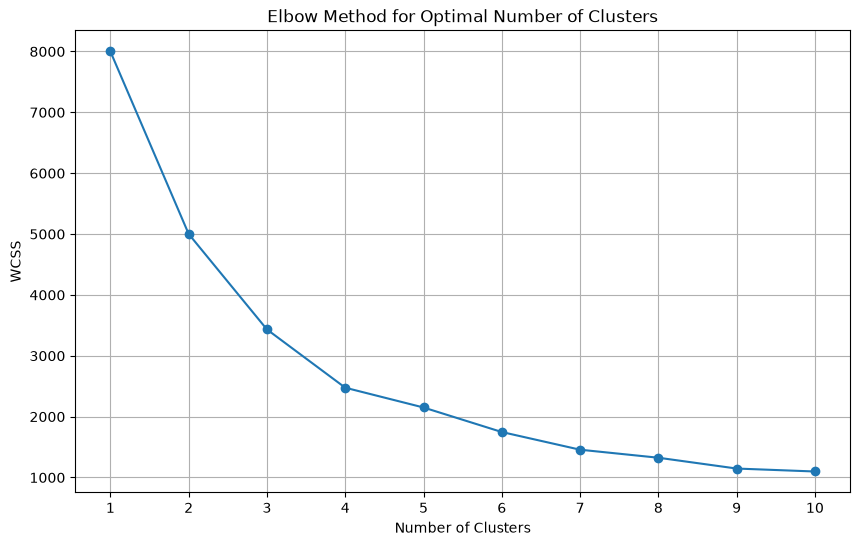

In [37]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=1
    )

    kmeans.fit(cluster_data_scaled)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')

plt.xticks(range(1, 11))
plt.grid()

plt.show()

In [38]:
from sklearn.cluster import KMeans

# Apply K-Means with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=1
)

kmeans_labels = kmeans.fit_predict(cluster_data_scaled)

# Add cluster labels
cluster_data['Cluster'] = kmeans_labels

print("Number of students in each cluster:")
print(
    cluster_data['Cluster']
    .value_counts()
    .sort_index()
)

Number of students in each cluster:
Cluster
0    1001
1     910
2    1074
3    1015
Name: count, dtype: int64


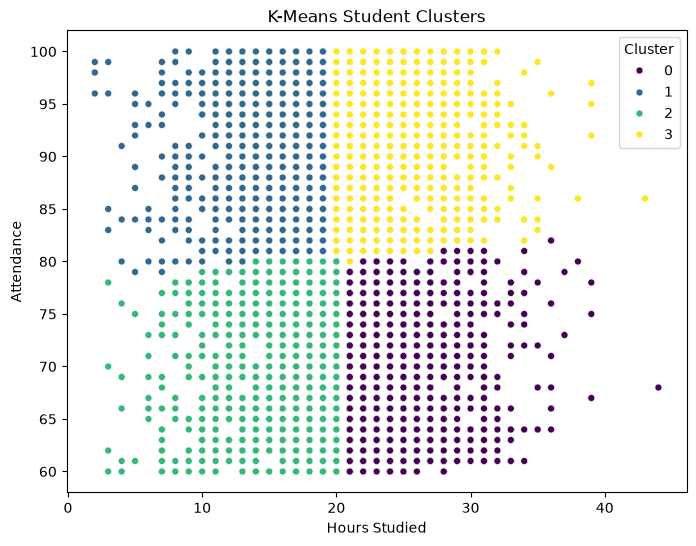

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x='Hours_Studied',
    y='Attendance',
    hue='Cluster',
    data=cluster_data,
    palette='viridis',
    s=25
)

plt.title('K-Means Student Clusters')
plt.xlabel('Hours Studied')
plt.ylabel('Attendance')
plt.legend(title='Cluster')

plt.show()

In [40]:
# Show average characteristics of each K-Means cluster
kmeans_averages = cluster_data.groupby('Cluster')[
    ['Hours_Studied', 'Attendance']
].mean().round(2)

print("K-Means Cluster Averages:")
print(kmeans_averages)

K-Means Cluster Averages:
         Hours_Studied  Attendance
Cluster                           
0                25.16       70.48
1                14.81       90.26
2                15.71       70.26
3                24.29       90.37


###	Hierarchical Clustering

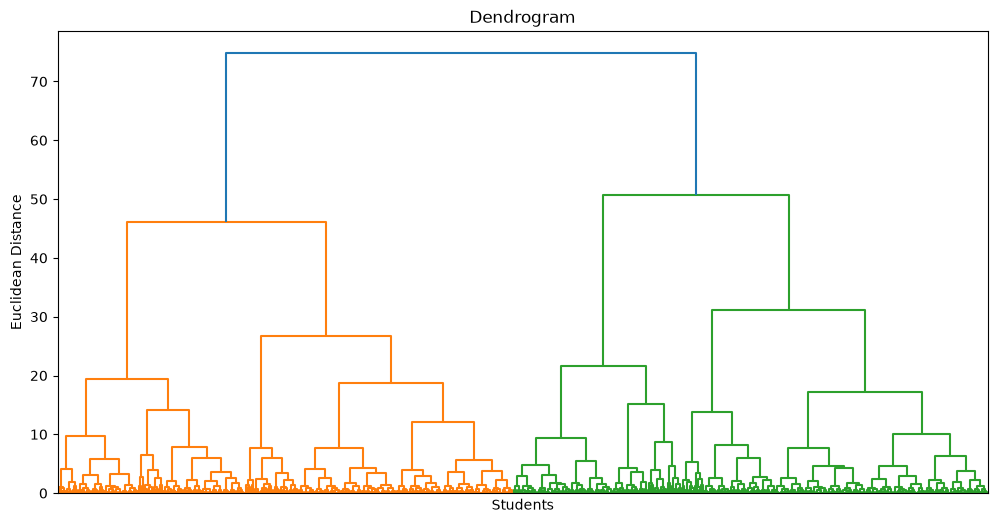

In [41]:
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

dendrogram = sch.dendrogram(
    sch.linkage(
        cluster_data_scaled,
        method='ward'
    ),
    no_labels=True
)

plt.title('Dendrogram')
plt.xlabel('Students')
plt.ylabel('Euclidean Distance')

plt.show()

In [42]:
from sklearn.cluster import AgglomerativeClustering

# Apply Hierarchical Clustering with 4 clusters
hc = AgglomerativeClustering(
    n_clusters=4,
    metric='euclidean',
    linkage='ward'
)

hierarchical_labels = hc.fit_predict(cluster_data_scaled)

cluster_data['Hierarchical_Cluster'] = hierarchical_labels

print("Number of students in each hierarchical cluster:")
print(
    cluster_data['Hierarchical_Cluster']
    .value_counts()
    .sort_index()
)

Number of students in each hierarchical cluster:
Hierarchical_Cluster
0    1313
1    1152
2     726
3     809
Name: count, dtype: int64


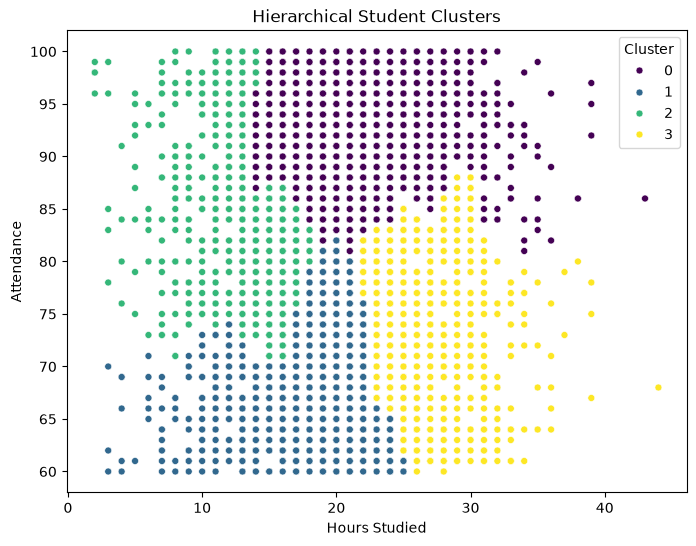

In [43]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x='Hours_Studied',
    y='Attendance',
    hue='Hierarchical_Cluster',
    data=cluster_data,
    palette='viridis',
    s=25
)

plt.title('Hierarchical Student Clusters')
plt.xlabel('Hours Studied')
plt.ylabel('Attendance')
plt.legend(title='Cluster')

plt.show()

In [44]:
hierarchical_averages = cluster_data.groupby(
    'Hierarchical_Cluster'
)[
    ['Hours_Studied', 'Attendance']
].mean().round(2)

print("Hierarchical Cluster Averages:")
print(hierarchical_averages)

Hierarchical Cluster Averages:
                      Hours_Studied  Attendance
Hierarchical_Cluster                           
0                             21.81       92.02
1                             17.98       68.53
2                             12.96       83.63
3                             26.51       73.42
